# Livrable final — Optimisation CVRPTW

**CESI — Algorithmique et optimisation — ILS optimisée et recuit décomposé**

Édition expérimentale du 11 novembre 2026.

## 1. Problème et démarche

Une tournée utile doit livrer tous ses clients à l'heure, transporter leurs demandes et revenir au dépôt. Notre objectif expérimental est la distance totale, sous capacités et fenêtres strictes. Les références DIMACS utilisent le même objectif et la même troncature par arc. Le nombre de véhicules est un maximum autorisé ; réduire la distance ne permet jamais de violer une contrainte.

Le sujet initial évoque une durée et du trafic variable. Notre périmètre retient des trajets fixes et symétriques. La distance de benchmark, la somme des durées avec services et attente, et le retour du dernier camion restent des indicateurs distincts. Cette édition optimise la distance ; elle ne revendique pas une optimisation du trafic ni de la somme des durées. Les distances abstraites ne sont pas converties en émissions réelles de CO₂.

La démarche relie modèle, code, vérification et mesures. L'édition initiale ILS/recuit a fourni 1 120 essais ; ses résultats sont conservés et identifiés comme **v1**. La révision **v2** teste ses modifications sur un lot de développement, fige les paramètres puis évalue un lot équilibré. Aucun résultat historique n'est réattribué au nouveau moteur.

La validation v2 comporte **36 instances × 5 graines × 2 méthodes = 360 trajectoires**, avec douze instances par taille. Le diagnostic avant/après conserve vingt graines sur chacun de deux cas. La calibration séparée totalise 324 essais ; aucun de ces essais ne remplace ceux de validation.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'algo/optimized.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from IPython.display import Image,display
from algo.data import load
from algo.solver import solve,production_settings,warmup
from algo.verify import verify
data=json.loads((ROOT/'results/optimization_v2/validation/analysis.json').read_text())
assert data['complete'] and data['runs']==360 and data['instances']==36
print('Validation complète :',data['runs'],'trajectoires,',data['instances'],'instances.')
warmup();


Validation complète : 360 trajectoires, 36 instances.


## 2. Données, horaires et formulation

### 2.1. Une solution et son évaluation

Une solution est une liste de tournées : `[[1,3],[2,4]]` signifie dépôt → 1 → 3 → dépôt et dépôt → 2 → 4 → dépôt. Le dépôt est implicite dans les listes. Les données contiennent coordonnées, demandes, services, fenêtres, matrices de trajet et distance, capacité et flotte maximale.

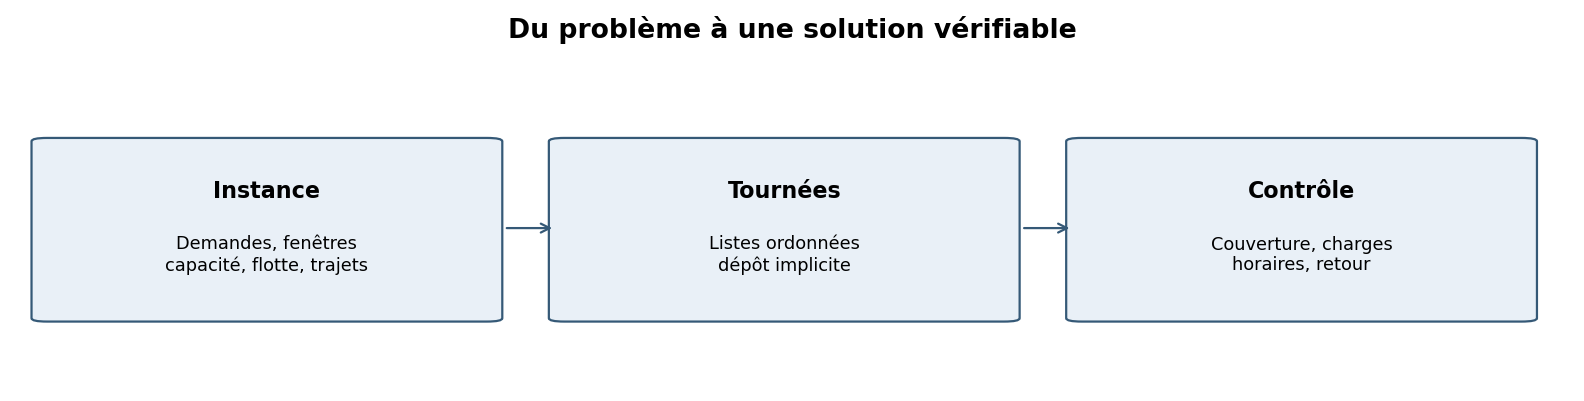

In [2]:
display(Image(filename=str(ROOT/'livraison/ils_figures/representation.png')))

**Lecture.** Les données définissent les contraintes ; les listes proposent un ordre. Le contrôleur recalcule les horaires et la couverture. Une carte satisfaisante visuellement ne prouve pas la faisabilité.

Pour deux visites successives i puis j, avec départ fixé à zéro et service nul au dépôt :

$$a_j=t_i+s_i+c_{ij},\qquad t_j=\max(a_j,e_j),\qquad b_j=t_j+s_j.$$

L'arrivée est a, le début du service t et sa fin b. L'attente est $t_j-a_j$. La fenêtre borne le début : $e_j\le t_j\le l_j$, bornes comprises. Une arrivée anticipée permet d'attendre ; la fin du service peut dépasser $l_j$ si la suite et le retour restent réalisables.

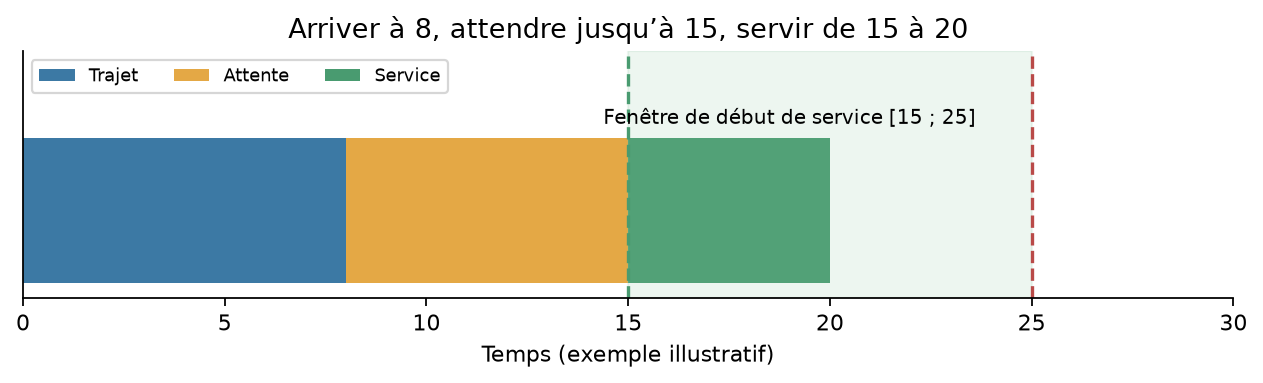

In [3]:
display(Image(filename=str(ROOT/'livraison/ils_figures/schedule.png')))

**Lecture.** Le trajet, l'attente et le service occupent trois périodes distinctes. Les fenêtres strictes n'interdisent pas d'arriver avant l'ouverture.

Pour un véhicule k, soit $R_k$ son retour, nul s'il est inutilisé. La distance D somme les arcs parcourus ; la durée totale est $\sum_k R_k$ et le makespan est $\max_k R_k$. Deux solutions de même distance peuvent avoir des attentes différentes.

### 2.2. Formulation PLNE complète et lecture des contraintes

Nous formalisons le **même CVRPTW que celui du projet** : un dépôt unique, des véhicules homogènes, des livraisons indivisibles, une tournée au plus par véhicule et des trajets fixes et symétriques. L'attente avant ouverture est autorisée. Le début du service doit appartenir à la fenêtre du client et le retour doit respecter la fermeture du dépôt. Les bornes sont inclusives. Le trafic variable, les ramassages, les dépôts multiples et les flottes hétérogènes ne font pas partie des expériences réalisées.

**Ensembles et indices.** Le nombre de clients est l'entier $n\ge1$. Leur ensemble est $C=\{1,\ldots,n\}$. Le nombre maximal de véhicules est l'entier $K\ge0$ et leur ensemble d'indices est $\mathcal K=\{1,\ldots,K\}$. Ainsi, $n$ et $K$ sont des nombres ; $C$ et $\mathcal K$ sont des ensembles. L'écriture $\forall i\in C$ signifie « pour chaque client i appartenant à C ». Elle ne désigne pas une boucle « tant que ».

Nous représentons le dépôt physique par deux sommets : $o$ pour le départ et $r$ pour le retour. Cette duplication permet de distinguer les heures de départ et de retour ; elle n'ajoute pas un deuxième dépôt réel. Les sommets et arcs autorisés sont :

$$V=C\cup\{o,r\},$$
$$A=(\{o\}\times C)\cup\{(i,j)\in C\times C:i\ne j\}\cup(C\times\{r\}).$$

Les véhicules peuvent aller du départ à un client, entre deux clients distincts, puis d'un client au retour. Aucune boucle sur un même sommet n'est autorisée. Aucun arc n'entre dans o et aucun arc ne quitte r.

**Paramètres.** Pour chaque client $i\in C$, soient $q_i,s_i,e_i,l_i\in\mathbb R_{\ge0}$ : sa demande est $q_i$, sa durée de service $s_i$ et sa fenêtre de début de service $[e_i,l_i]$. Soient $Q,H\in\mathbb R_{>0}$ la capacité commune et la fermeture du dépôt. Comme dans les données acceptées par `Instance`, nous supposons $0\le e_i\le l_i\le H$ pour tout $i\in C$. Pour chaque arc $(i,j)\in A$, soient $d_{ij},c_{ij}\in\mathbb R_{\ge0}$ sa distance et son temps de trajet. Les départs sont fixés au temps zéro. Dans les benchmarks du projet, temps de trajet et distances ont les mêmes valeurs numériques ; le modèle distingue néanmoins leurs rôles et leurs unités.

**Variables de décision et domaines.**

$$x_{ij}^k\in\{0,1\}\quad\forall(i,j)\in A,\ \forall k\in\mathcal K.$$

Pour chaque arc et chaque véhicule, x vaut un si le véhicule emprunte cet arc, et zéro sinon.

$$y_i^k\in\{0,1\}\quad\forall i\in C,\ \forall k\in\mathcal K,\qquad
u_k\in\{0,1\}\quad\forall k\in\mathcal K.$$

La variable y vaut un si le client i est affecté au véhicule k. La variable u vaut un si le véhicule k est utilisé.

$$t_i\in\mathbb R_{\ge0}\quad\forall i\in C,\qquad
R_k\in\mathbb R_{\ge0}\quad\forall k\in\mathcal K.$$

La variable t est l'heure de **début du service**, pas l'heure d'arrivée. La variable R est l'heure de retour au dépôt. Les bornes horaires sont imposées ci-dessous.

Enfin, $f_{ij}^k\in\mathbb R_{\ge0}$, pour chaque $(i,j)\in A$ et chaque $k\in\mathcal K$, est un flot artificiel assurant la connexion au dépôt. Il représente un outil mathématique, pas la marchandise dans le camion.

**Objectif du benchmark : distance totale.**

$$\min D=\sum_{k\in\mathcal K}\sum_{(i,j)\in A}d_{ij}x_{ij}^k.$$

Nous additionnons les distances des arcs parcourus par tous les véhicules. Le nombre de camions est un maximum autorisé, sans priorité lexicographique ni coût fixe ajouté. La durée totale avec attente est étudiée séparément ; son coût ne doit pas être comparé à une référence en distance.

**C1 — Affecter chaque client exactement une fois.**

$$\sum_{k\in\mathcal K}y_i^k=1\qquad\forall i\in C.$$

Pour chaque client i, la somme des affectations vaut un : un seul véhicule réalise l'intégralité de sa livraison. Aucun client ne peut être oublié ou réparti entre plusieurs camions.

**C2 — Assurer une entrée et une sortie avec le véhicule affecté.**

$$\sum_{j:(j,i)\in A}x_{ji}^k=y_i^k,
\qquad\sum_{j:(i,j)\in A}x_{ij}^k=y_i^k
\qquad\forall i\in C,\ \forall k\in\mathcal K.$$

Pour chaque client et chaque véhicule, une affectation impose exactement une entrée et une sortie. Sans affectation, ce véhicule n'emprunte aucun arc entrant ou sortant de ce client. Les indices des sommes sont limités aux arcs autorisés de A.

**C3 — Partir du dépôt et y revenir, au plus une fois par véhicule.**

$$\sum_{j\in C}x_{oj}^k=u_k,
\qquad\sum_{i\in C}x_{ir}^k=u_k
\qquad\forall k\in\mathcal K.$$

Chaque véhicule utilisé effectue un départ et un retour. Un véhicule inutilisé n'en effectue aucun. On autorise donc l'utilisation de moins de K camions. La borne $\sum_{k\in\mathcal K}u_k\le K$ est automatiquement satisfaite, puisque u est binaire et que $\mathcal K$ contient K véhicules.

**C4 — Respecter la capacité de chaque camion.**

$$\sum_{i\in C}q_iy_i^k\le Qu_k
\qquad\forall k\in\mathcal K.$$

Pour chaque véhicule, la somme des quantités affectées ne dépasse pas Q. Cette somme est la charge à emporter au départ pour des livraisons pures. Elle diminue ensuite pendant la tournée ; il n'y a aucun ramassage. Le code peut donc contrôler la même contrainte en additionnant les demandes de la tournée. Les unités de demande ne sont pas multipliées par dix.

**C5 — Commencer le service dans la fenêtre du client.**

$$e_i\le t_i\le l_i\qquad\forall i\in C.$$

Pour chaque client, le début du service se situe entre ouverture et fermeture, bornes comprises. Une arrivée avant l'ouverture est possible avec attente. La fin $t_i+s_i$ peut dépasser $l_i$ : notre projet n'impose pas une fenêtre sur la fin du service.

**C6 — Respecter l'ordre temporel des trajets et services.**

Posons $s_{\max}=\max_{i\in C}s_i$, $c_{\max}=\max_{(i,j)\in A}c_{ij}$ et $M=H+s_{\max}+c_{\max}$. Cette borne est valide sous les hypothèses d'horizon précédentes.

$$t_j\ge c_{oj}-M(1-x_{oj}^k)
\qquad\forall j\in C,\ \forall k\in\mathcal K.$$

Pour chaque client j et chaque véhicule k, si l'arc du dépôt vers j est utilisé, le service ne commence pas avant la fin du trajet depuis le départ au temps zéro.

$$t_j\ge t_i+s_i+c_{ij}-M(1-x_{ij}^k)
\qquad\forall i,j\in C,\ i\ne j,\ \forall k\in\mathcal K.$$

Pour chaque paire de clients distincts et chaque véhicule, emprunter l'arc de i vers j impose de terminer le service chez i puis le trajet avant de commencer chez j. Si cet arc n'est pas utilisé, M désactive l'implication. Une borne par arc pourrait renforcer une résolution exacte sans changer les règles métier.

Le PLNE impose l'existence d'horaires réalisables, sans exiger systématiquement les horaires au plus tôt pour l'objectif distance. Une fois l'ordre fixé, `verify()` recalcule les horaires au plus tôt : arrivée = fin précédente + trajet ; début = maximum entre arrivée et ouverture ; fin = début + service.

**C7 — Fixer le retour et respecter la fermeture du dépôt.**

$$R_k\ge t_i+s_i+c_{ir}-M(1-x_{ir}^k),$$
$$R_k\le t_i+s_i+c_{ir}+M(1-x_{ir}^k)
\qquad\forall i\in C,\ \forall k\in\mathcal K,$$
$$0\le R_k\le Hu_k\qquad\forall k\in\mathcal K.$$

Pour chaque client et chaque véhicule, si i est le dernier client visité, les deux premières inégalités fixent le retour à la fin de son service plus le trajet vers le dépôt. Le retour doit être au plus H. Pour un véhicule inutilisé, R vaut zéro. Un retour exactement à H est autorisé.

**C8 — Interdire les cycles de clients isolés du dépôt.**

$$0\le f_{ij}^k\le nx_{ij}^k
\qquad\forall(i,j)\in A,\ \forall k\in\mathcal K,$$
$$f_{ir}^k=0\qquad\forall i\in C,\ \forall k\in\mathcal K.$$

Le flot artificiel ne passe que sur un arc utilisé. Il fournit une unité par client et n'a plus rien à transporter lors du retour au dépôt.

$$\sum_{j:(j,i)\in A}f_{ji}^k-\sum_{j:(i,j)\in A}f_{ij}^k=y_i^k
\qquad\forall i\in C,\ \forall k\in\mathcal K,$$
$$\sum_{j\in C}f_{oj}^k=\sum_{i\in C}y_i^k
\qquad\forall k\in\mathcal K.$$

Chaque client affecté consomme une unité reçue du dépôt. Le dépôt en émet autant que de clients affectés au véhicule. Un cycle isolé ne peut pas satisfaire cette consommation : en additionnant les équations de ses clients, tous les flots internes s'annulent alors qu'une consommation strictement positive resterait nécessaire. Le flot empêche ainsi les sous-tournées, même lorsque des temps tronqués sont nuls.

**Convention numérique et représentation dans le programme.** Les références DIMACS utilisent chaque arc euclidien tronqué à une décimale. `algo/data.py` calcule sa valeur entière à l'échelle dix et multiplie fenêtres et services par dix. Les coûts affichés sont reconvertis. Les dépôts o et r du PLNE correspondent tous deux à l'indice 0 du code ; les retours sont ajoutés implicitement aux listes de tournées. Les contraintes restent obligatoires, quelle que soit la métaheuristique choisie.



**Pourquoi le grand M est valide.** Les bornes $0\le t_i,t_j\le H$ impliquent $t_i+s_i+c_{ij}-t_j\le H+s_{\max}+c_{\max}$. Cette valeur désactive donc la propagation d'un arc non utilisé. Des bornes par arc peuvent renforcer le solveur exact sans modifier les solutions autorisées. Le modèle contient de l'ordre de $Kn^2$ variables d'arcs/flots et contraintes : l'exact sert ici aux petits cas.

## 3. Complexité et contrôle exact

Pour une entrée rationnelle et un seuil B, la décision demande s'il existe une solution réalisable de distance au plus B. Un certificat donne les tournées ; couverture, charges, horaires et coût se vérifient en temps polynomial dans la taille binaire de l'entrée.

Un TSP symétrique à coûts positifs se réduit au problème : un véhicule, demandes unitaires, capacité n, services nuls, temps égaux aux coûts, horizon $H=(n+1)c_{\max}$ et fenêtres [0,H]. Les contraintes deviennent non bloquantes et les circuits de même coût se correspondent. La transformation est polynomiale : la décision générale est NP-complète et l'optimisation NP-difficile. Cela n'interdit pas de résoudre exactement certains petits cas.

Le module `controle/plne.py` traduit réellement C1–C8 dans SciPy/HiGHS. Une borne inférieure, une solution réalisable et une preuve d'optimalité ont des statuts distincts. Les dix petits cas de contrôle sont conservés ; ils valident le modèle et ne constituent pas des références pour les grandes instances.

| clients | graine | statut | coût | borne | temps |
| --- | --- | --- | --- | --- | --- |
| 4 | 11 | optimal | 147,000 | 147,000 | 0,009 |
| 4 | 22 | optimal | 113,200 | 113,200 | 0,004 |
| 6 | 11 | optimal | 187,700 | 187,700 | 0,019 |
| 6 | 22 | optimal | 178,500 | 178,500 | 0,018 |
| 8 | 11 | optimal | 187,700 | 187,700 | 0,052 |
| 8 | 22 | optimal | 181,700 | 181,700 | 0,123 |
| 10 | 11 | optimal | 198,400 | 198,400 | 0,153 |
| 10 | 22 | optimal | 190,300 | 190,300 | 0,391 |
| 12 | 11 | time_limit | 242,700 | 223,300 | 8,074 |
| 12 | 22 | optimal | 215,800 | 215,800 | 0,662 |

HiGHS certifie 9/10 optimums. La ligne à limite de temps conserve son incumbent et sa borne ; elle n'est pas appelée optimale.

## 4. Méthodes et améliorations retenues

### 4.1. Construire un départ commun

Le constructeur essaie douze insertions par regret-2 : une sans bruit, puis onze avec un classement perturbé. Pour un client i, si les deux meilleurs surcoûts réalisables dans des tournées distinctes sont $\Delta_i^{(1)}\le\Delta_i^{(2)}$, son regret est $r_i=\Delta_i^{(2)}-\Delta_i^{(1)}$. Les clients avec peu d'alternatives sont prioritaires. Le meilleur départ complet est gardé ; un échec de construction ne prouve pas une impossibilité.

**Entrées :** instance, graine et nombre d'essais. **Sorties :** listes de tournées et coût/temps de construction. La recherche ne lit aucune BKS. Le même départ est donné aux méthodes comparées et son temps est publié séparément.

```python
def construct(ins, seed=0, attempts=12):
    """Try regret-2 starts and return the cheapest feasible complete solution.

    Inputs are the immutable instance, a random seed and the number of attempts.
    The returned pair contains route lists (or None) and construction metrics.
    No BKS or stored benchmark solution is read by the constructor.
    """
    start = time.perf_counter()
    rng = random.Random(seed)
    best = math.inf
    routes = None
    for attempt in range(attempts):
        a, l = encode([], ins)
        if k.repair_fast(
            a,
            l,
            len(l) - 1,
            *arrays(ins),
            2,
            0.0 if attempt == 0 else 0.2,
            rng.randrange(2**31)
        ):
            count, cost = k.total(a, l, *arrays(ins))
            if count >= 0 and cost < best:
                best = cost
                routes = decode(a, l)
    return routes, dict(
        seconds=time.perf_counter() - start,
        attempts=attempts,
        cost=best / 10 if routes is not None else None,
    )
```

**Lecture du code.** Chaque essai commence avec des tableaux vides. `repair_fast` est utilisé uniquement pour construire cette première solution ; le meilleur coût réalisable est copié. Les recherches suivantes utilisent des mouvements sur des tournées complètes, sans retirer des clients dans une réserve à réparer.

### 4.2. Recherche locale itérée et recuit directs

L'ILS copie la courante, cherche jusqu'à quatre perturbations réalisables puis applique une recherche locale bornée. Elle accepte la candidate si $D(S')\le1{,}005D(S^*)$, où $S^*$ est le record. Toute amélioration stricte met à jour une copie de l'archive. Après cent cycles sans record, elle repart de cette archive.

Le recuit propose relocate, swap, inversion 2-opt ou échange de fins 2-opt*. Après contrôle de faisabilité, avec $\Delta=D(S')-D(S)$ et $T>0$ :

$$P(\mathrm{acceptation})=1\text{ si }\Delta\le0,\qquad P=\exp(-\Delta/T)\text{ sinon.}$$

Une archive indépendante protège le record. Avec un budget local b et le temps consommé $\tau$, le refroidissement est $T(\tau)=T_0(0{,}005)^{\min(1,\tau/b)}$. Les modes de température et de voisinage ont été comparés, sans supposer qu'un refroidissement plus froid améliore toujours les résultats.

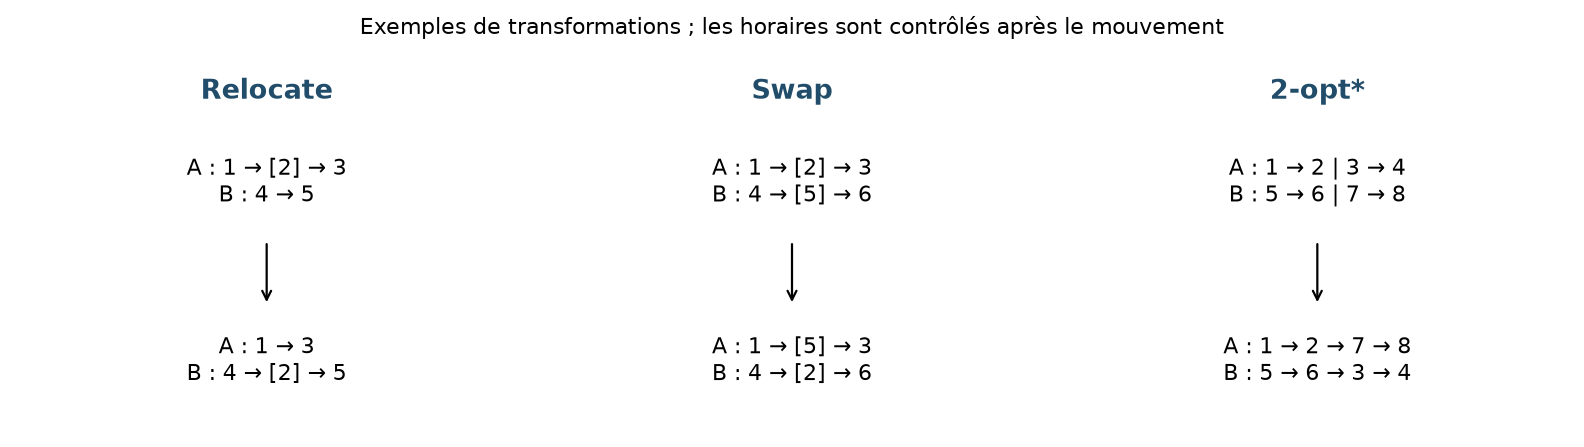

In [4]:
display(Image(filename=str(ROOT/'livraison/ils_figures/moves.png')))

**Lecture.** Les mouvements changent ordre ou affectation. Les tournées touchées sont réévaluées ; une baisse géométrique ne compense jamais une surcharge ou un retard.

**`walk` :** reçoit les tableaux et paramètres, propose les mouvements et renvoie le meilleur état ainsi que des compteurs. Le passage ci-dessous est extrait du vrai corps de fonction.

```python
        delta = ca - costs[a] + (cb - costs[b] if b != a else 0.0)
        valid += 1
        take = mode == 0 or delta <= 1e-9
        if not take and mode == 1:
            take = np.random.random() < math.exp(
                -min(745.0, delta / max(temperature, 1e-12))
            )
```

**Lecture.** Le coût marginal est calculé après les contrôles. Un gain est accepté ; une hausse est tirée selon Metropolis. Les compteurs distinguent les refus par capacité, horaires, structure et acceptation probabiliste. Ils concernent les propositions directes, pas tous les candidats internes de recherche locale.

### 4.3. Optimiser des groupes de tournées

Le diagnostic v1 montrait des mouvements rarement réalisables et une difficulté sur R1_10_1. La révision optimise des groupes de tournées géographiquement voisines. Elle conserve les demandes, capacités, services, fenêtres, distances et temps originaux. Les dépôts de chaque groupe représentent le même dépôt physique. La flotte disponible tient compte des tournées laissées à l'extérieur.

L'ILS adapte la taille cible aux longueurs des tournées : pour m tournées utilisées, $G=\max(120,\min(360,8\lceil n/m\rceil))$. Le groupe est une sélection de tournées entières, non une garantie de cardinalité exacte. Sur les petites instances, la recherche reste directe. Le recuit emploie la configuration sélectionnée sur le développement.

Un groupe contient au plus douze tournées. La sous-recherche dispose de 0,2 seconde par appel et peut utiliser jusqu'à trois véhicules supplémentaires, sous la flotte globale restante. Ces limites règlent le voisinage et le travail de recherche ; elles n'autorisent aucune violation du problème initial. La vérification globale contrôle à nouveau le nombre total de véhicules.

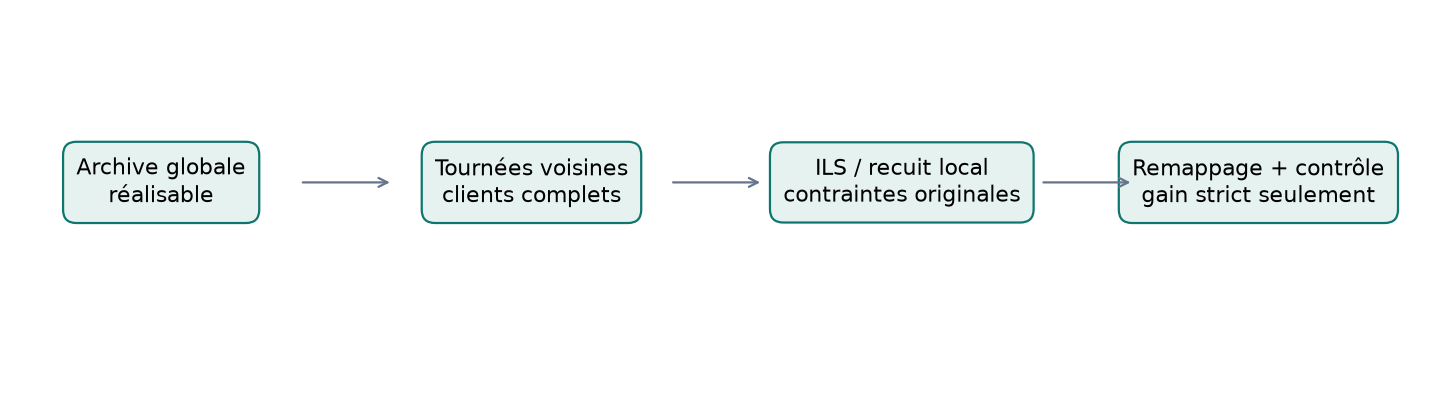

In [5]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_groups.png')))

**Lecture.** Une sous-recherche modifie toutes les tournées choisies avec des solutions complètes. Les clients sont ensuite remappés vers leurs identifiants originaux. Le contrôleur vérifie la solution globale ; elle est remplacée seulement si la distance diminue. Aucun appel de réparation n'est utilisé pendant cette phase.

**`solve` :** reçoit instance, budget, graine et départ éventuel. Il garde une archive, lance les recherches de groupes sous le budget global puis retourne une solution vérifiée. L'extrait montre la réintégration et l'acceptation réelle.

```python
        proposal = [
            route for index, route in enumerate(routes) if index not in selected_set
        ]
        proposal.extend(
            [[mapping[client] for client in route] for route in result["routes"]]
        )
        candidate = verify(proposal, ins)
        if not candidate["valid"]:
            raise AssertionError(candidate["errors"])
        distance = candidate["distance"] / 10
        if distance < best - 1e-8:
            routes, best = proposal, distance
            improvements += 1
```

### 4.4. Un mouvement complet sur un petit exemple

In [6]:
import numpy as np
from algo.model import Instance
from algo.iterated import arrays,encode,decode,build_neighbors
from algo.direct import walk
xy=np.array([[0,0],[1,0],[0,10],[2,0],[0,11]],float)
d=np.floor(10*np.sqrt(((xy[:,None,:]-xy[None,:,:])**2).sum(axis=2)))
toy=Instance('mouvement',xy,np.array([0,1,1,1,1]),np.zeros(5),np.zeros(5),np.full(5,1000.),d,2.,2,1000.)
before=[[1,2],[3,4]]
a,lengths=encode(before,toy)
movement=walk(a,lengths,len(lengths)-1,*arrays(toy),build_neighbors(toy,4),2000,519,0.,1)
after=decode(movement[1],movement[2])
control=verify(after,toy)
assert control['valid'] and control['distance']<verify(before,toy)['distance']
print(before,'->',after)
print('Distance avant :',verify(before,toy)['distance']/10,'; après :',control['distance']/10)


[[1, 2], [3, 4]] -> [[1, 3], [4, 2]]
Distance avant : 45.1 ; après : 26.0


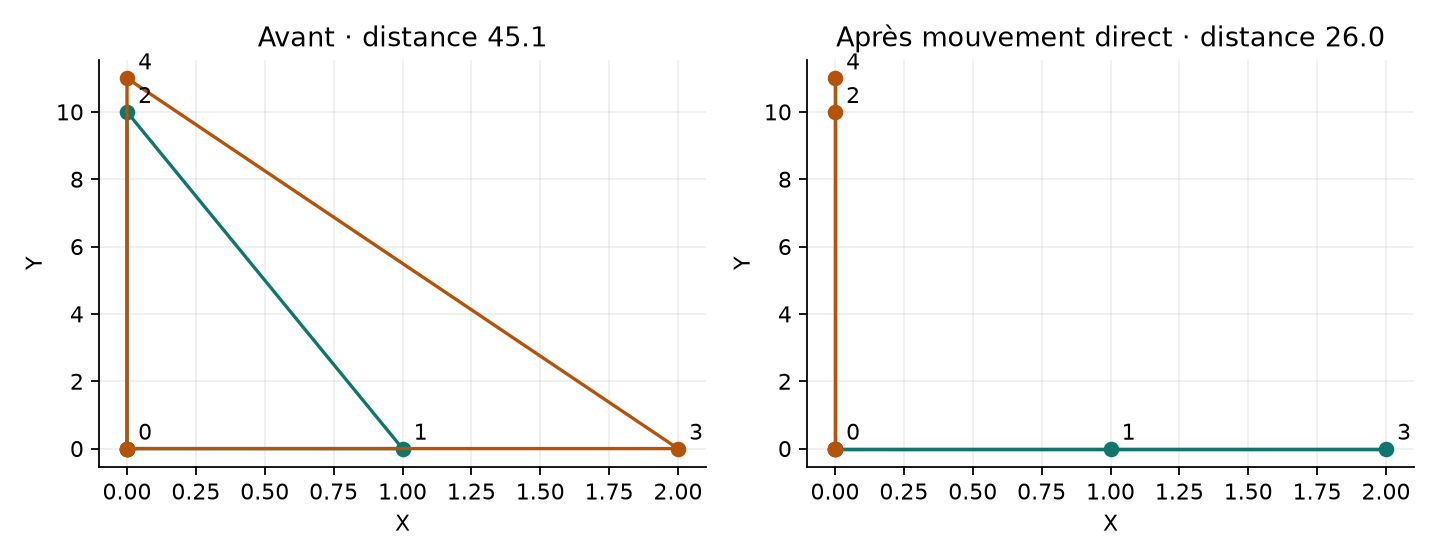

In [7]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_example.png')))

**Lecture.** Les deux solutions illustrées couvrent les mêmes clients avec la même capacité et les mêmes fenêtres. Le mouvement modifie leur affectation et raccourcit les trajets. C'est une démonstration du code sur un jouet, sans BKS ni prétention de performance générale.

### 4.5. Réglages testés et décisions

La calibration comprend six instances à 100 clients et une instance par famille à 1 000 clients, avec trois graines. Des groupes fixes, un voisinage temporel, SWAP*, deux échelles de température puis des groupes adaptatifs sont mesurés. Les essais supplémentaires ont leur protocole distinct. Les configurations sont figées avant la validation ; les résultats défavorables sont conservés.

| Clients | Méthode | Essais | Gap moyen (%) | Pire gap (%) |
| --- | --- | --- | --- | --- |
| 100 | ils_groups | 18 | 0,793 | 2,702 |
| 100 | ils_groups240 | 18 | 0,793 | 2,702 |
| 100 | ils_swap_star | 18 | 1,594 | 5,591 |
| 100 | ils_temporal | 18 | 0,597 | 2,425 |
| 100 | sa_edge | 18 | 0,928 | 2,438 |
| 100 | sa_total | 18 | 1,274 | 4,083 |
| 1000 | ils_groups | 18 | 11,949 | 24,004 |
| 1000 | ils_groups240 | 18 | 9,275 | 17,954 |
| 1000 | ils_swap_star | 18 | 14,701 | 33,998 |
| 1000 | ils_temporal | 18 | 11,559 | 24,683 |
| 1000 | sa_edge | 18 | 17,100 | 38,697 |
| 1000 | sa_total | 18 | 13,955 | 28,015 |
| 100 | ils_adaptive | 18 | 0,793 | 2,702 |
| 100 | sa_adaptive | 18 | 1,008 | 2,973 |
| 100 | sa_groups240 | 18 | 1,073 | 4,601 |
| 1000 | ils_adaptive | 18 | 8,887 | 15,504 |
| 1000 | sa_adaptive | 18 | 14,186 | 30,259 |
| 1000 | sa_groups240 | 18 | 14,238 | 33,495 |

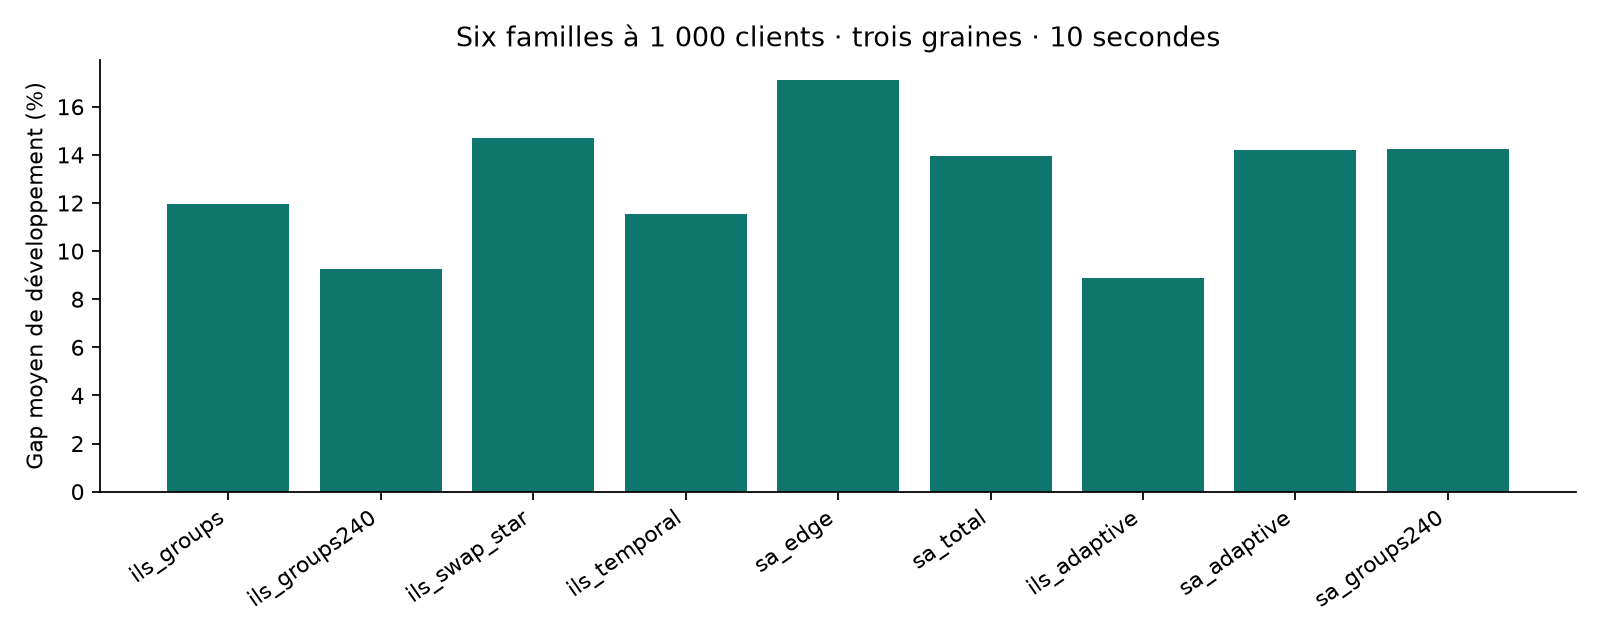

In [8]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_development.png')))

Le profil ILS retenu est `ils_adaptive` ; le recuit utilise `sa_total`. SWAP* et le voisinage temporel restent des options expérimentales : leur ajout n'a pas fourni la meilleure moyenne de développement à 1 000 clients. Refroidir davantage le recuit n'a pas gagné sur ce lot. Le choix utilise uniquement les données de développement, avant la validation.

## 5. Protocole équilibré et statistiques

### 5.1. Instances et budgets

| clients | instances | graines | méthodes | trajectoires | recherche_s |
| --- | --- | --- | --- | --- | --- |
| 100 | 12 | 5 | 2 | 120 | 5 |
| 200 | 12 | 5 | 2 | 120 | 6 |
| 1000 | 12 | 5 | 2 | 120 | 40 |

Les douze grandes instances couvrent C1, C2, R1, R2, RC1 et RC2. Elles sont différentes de celles utilisées pour la calibration v2. Certaines géographies avaient déjà été évaluées : il ne s'agit pas d'une validation totalement aveugle. Les cas diagnostiqués C204 et R1_10_1 sont traités dans une comparaison séparée à vingt graines.

Les grands cas conservent leur résultat à 25 secondes puis reçoivent tous une continuation de 15 secondes depuis l'archive. Ces continuations prolongent les mêmes trajectoires : elles n'ajoutent pas des runs indépendants. Le budget total, le résultat à 25 secondes et les deux phases sont publiés. La construction et le préchauffage sont mesurés séparément.

Les mesures ont été exécutées sous Windows avec Python 3.12.8, sur un processeur AMD à six cœurs physiques et douze processeurs logiques, avec environ 16 Gio de mémoire. Quatre processus servent la validation et deux la comparaison avant/après, avec des affinités logiques distinctes. Ils partagent mémoire, caches et refroidissement ; aucun facteur de vitesse universel n'est revendiqué. L'environnement complet est enregistré dans `results/optimization_v2/environment.json`.

| Bibliothèque | Version mesurée |
| --- | --- |
| numpy | 2.4.1 |
| pandas | 2.3.3 |
| numba | 0.68.1 |
| scipy | 1.18.1 |

### 5.2. Définition des indicateurs

Pour un essai réalisable e disposant d'une BKS compatible et positive :

$$g_e=100\left(\frac{D_e}{D_e^{\mathrm{BKS}}}-1\right).$$

Une BKS n'est pas nécessairement un optimum prouvé. Un échec reste dans les effectifs et ne reçoit pas de gap nul. Pour m gaps disponibles, $\bar g=m^{-1}\sum_e g_e$ et, si $m\ge2$, $s_g=\sqrt{\sum_e(g_e-\bar g)^2/(m-1)}$. Les écarts-types sont en points de pourcentage. Médiane, quartiles et pires cas complètent la moyenne. Les fréquences sous 5 %, 6 % et 7 % utilisent tous les essais prévus au dénominateur.

Le lot équilibré donne le même poids aux trois tailles, avec le même nombre d'instances et répétitions par taille. La moyenne globale est donc aussi la moyenne des trois moyennes par taille. Elle ne garantit pas le seuil pour chaque instance. Les différences de méthodes sont appariées par instance et graine ; les intervalles bootstrap par graines concernent ce benchmark fixé. Avec cinq blocs, l'incertitude reste exploratoire et la diversité géographique n'est pas remplacée par les répétitions.

Dans l'étude v1, 24 des 28 instances avaient 100 clients : elles pesaient 85,7 % de la moyenne globale, contre 7,1 % pour chacune des deux autres tailles. Dans la validation v2, chacune des trois tailles pèse 33,3 %. Les moyennes globales v1 et v2 ne mesurent donc pas la même population. Le gain algorithmique se juge dans une comparaison appariée à budget égal, et non en soustrayant ces deux moyennes de périmètres différents.

## 6. Résultats de la validation v2

| Méthode | Essais | Réalisables | Gap moyen (%) | Médiane (%) | Écart-type (pt) | Pire gap (%) | Sous 5 % | Sous 6 % | Sous 7 % |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS optimisée | 180 | 180 | 4,933 | 3,627 | 5,256 | 24,321 | 119 | 133 | 143 |
| Recuit décomposé | 180 | 180 | 4,100 | 2,873 | 4,335 | 17,410 | 139 | 150 | 150 |

Sur 180 paires, la différence moyenne ILS moins recuit est 0,833 point. L'intervalle bootstrap conditionnel à 95 % par blocs de graines est [0,472 ; 1,122] point. Avec cinq blocs, il reste exploratoire.

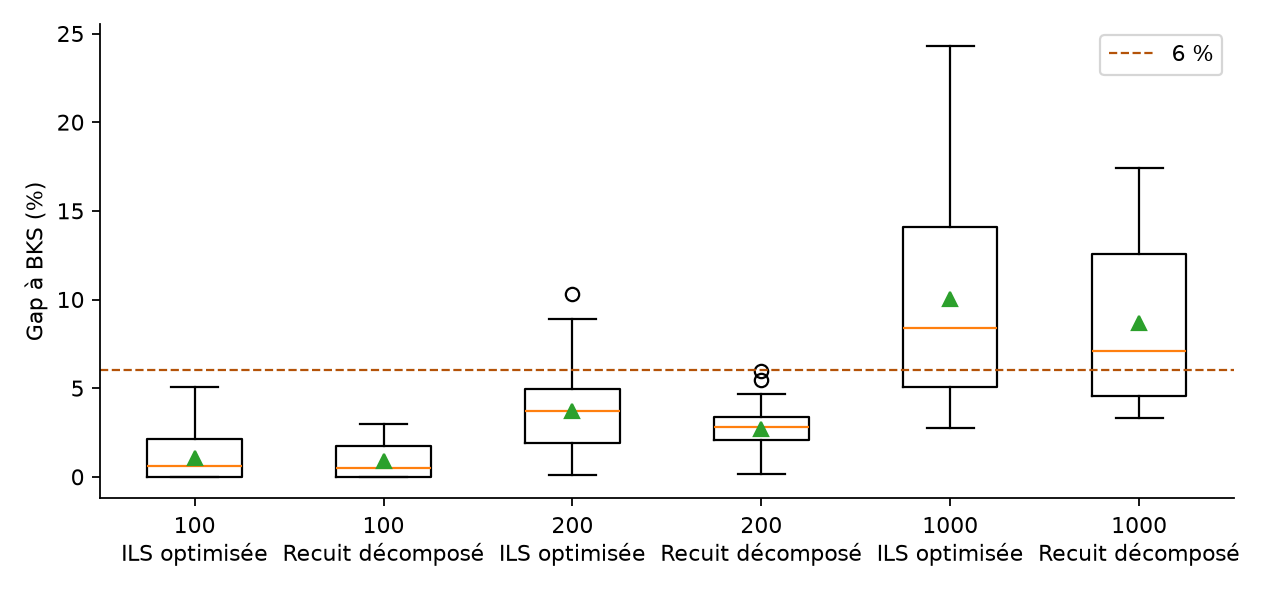

In [9]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_distribution.png')))

**Lecture.** Chaque boîte mélange la variabilité des graines et celle des instances de sa taille. Elle affiche la médiane et les quartiles ; les points défavorables restent inclus. Il faut lire le tableau par instance pour localiser les difficultés.

| Clients | Méthode | Essais | Gap moyen (%) | Pire gap (%) | Sous 5 % | Sous 6 % | Sous 7 % | Recherche (s) | Total (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 100 | ILS optimisée | 60 | 1,052 | 5,059 | 59 | 60 | 60 | 5,001 | 5,026 |
| 100 | Recuit décomposé | 60 | 0,883 | 2,959 | 60 | 60 | 60 | 5,001 | 5,025 |
| 200 | ILS optimisée | 60 | 3,692 | 10,307 | 47 | 52 | 55 | 6,001 | 6,114 |
| 200 | Recuit décomposé | 60 | 2,721 | 5,957 | 58 | 60 | 60 | 6,003 | 6,116 |
| 1000 | ILS optimisée | 60 | 10,055 | 24,321 | 13 | 21 | 28 | 40,018 | 44,401 |
| 1000 | Recuit décomposé | 60 | 8,696 | 17,410 | 21 | 30 | 30 | 40,017 | 44,400 |

À 100 clients : ILS 1,052 %, recuit 0,883 %. À 200 clients : ILS 3,692 %, recuit 2,721 %. À 1000 clients : ILS 10,055 %, recuit 8,696 %. Les cas encore au-dessus de 6 % en moyenne sont : C2_10_3, C2_10_4, R1_10_3, R2_10_3, R2_10_4, RC1_10_3, RC2_10_3, RC2_10_4. Sur ce lot équilibré, le recuit décomposé obtient une meilleure moyenne globale que l'ILS. L'amélioration de l'ILS sur R1_10_1 ne constitue donc pas une supériorité universelle. La cible inférieure à 6 % n'est pas atteinte sur l'ensemble des grands cas.

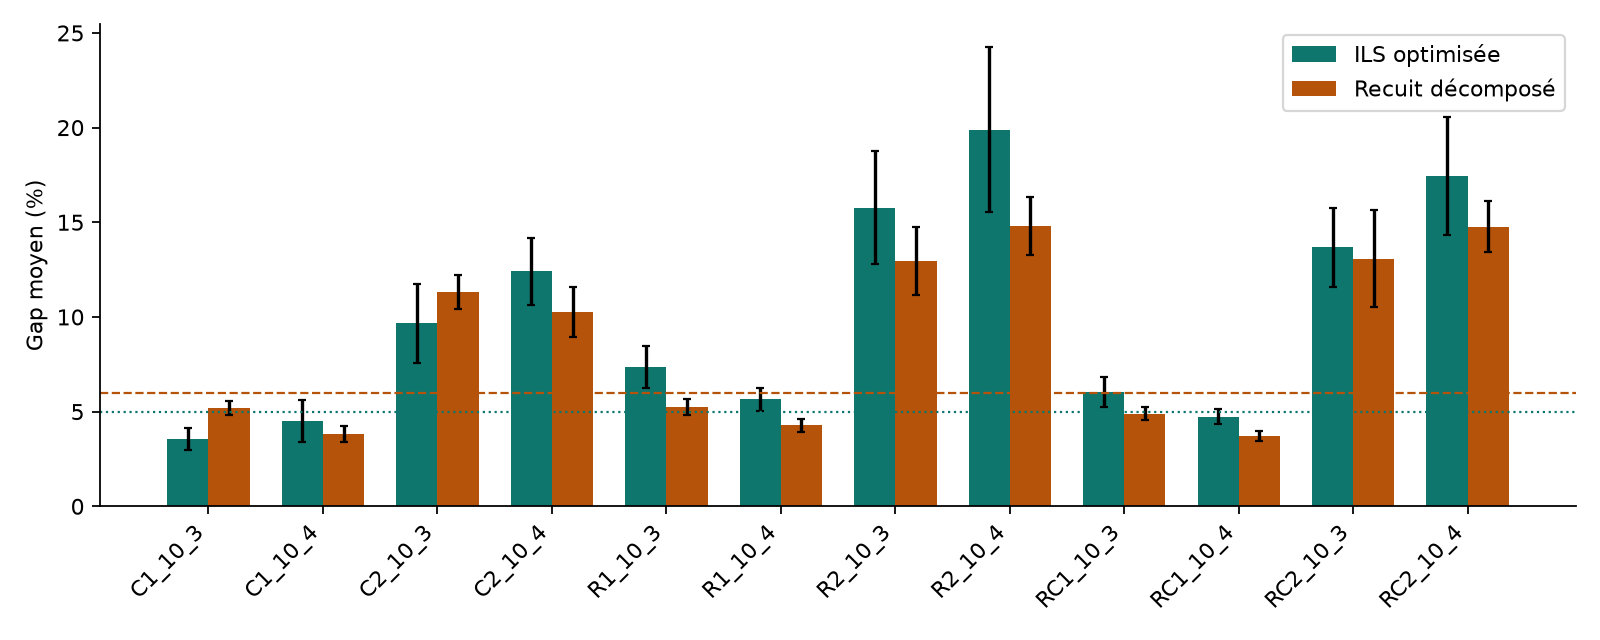

In [10]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_large.png')))

**Lecture.** Chaque barre représente cinq répétitions d'une grande instance ; les traits indiquent un écart-type, pas un intervalle de confiance. Les seuils et les pires cas restent des indicateurs distincts. Le tableau complet comporte BKS, distances, gaps et temps, y compris pour les essais défavorables.

| Instance | Méthode | Essais | Gap moyen (%) | Écart-type (pt) | Meilleur gap (%) | Pire gap (%) | Sous 6 % |
| --- | --- | --- | --- | --- | --- | --- | --- |
| C1_10_3 | ILS optimisée | 5 | 3,531 | 0,584 | 2,726 | 4,139 | 5 |
| C1_10_4 | ILS optimisée | 5 | 4,500 | 1,120 | 2,878 | 5,739 | 5 |
| C2_10_3 | ILS optimisée | 5 | 9,667 | 2,096 | 6,332 | 11,461 | 0 |
| C2_10_4 | ILS optimisée | 5 | 12,413 | 1,776 | 9,513 | 14,122 | 0 |
| R1_10_3 | ILS optimisée | 5 | 7,336 | 1,110 | 6,196 | 9,085 | 0 |
| R1_10_4 | ILS optimisée | 5 | 5,650 | 0,611 | 5,066 | 6,580 | 4 |
| R2_10_3 | ILS optimisée | 5 | 15,764 | 2,987 | 12,946 | 20,696 | 0 |
| R2_10_4 | ILS optimisée | 5 | 19,896 | 4,363 | 13,887 | 24,321 | 0 |
| RC1_10_3 | ILS optimisée | 5 | 6,042 | 0,799 | 4,960 | 7,145 | 2 |
| RC1_10_4 | ILS optimisée | 5 | 4,726 | 0,388 | 4,167 | 5,056 | 5 |
| RC2_10_3 | ILS optimisée | 5 | 13,672 | 2,065 | 11,438 | 15,730 | 0 |
| RC2_10_4 | ILS optimisée | 5 | 17,464 | 3,120 | 12,652 | 19,806 | 0 |

### 6.1. Effet du temps et convergence

| Méthode | Essais | Gap moyen à 25 s (%) | Gap moyen à 40 s (%) | Pire gap à 40 s (%) |
| --- | --- | --- | --- | --- |
| ILS optimisée | 60 | 10,890 | 10,055 | 24,321 |
| Recuit décomposé | 60 | 10,065 | 8,696 | 17,410 |

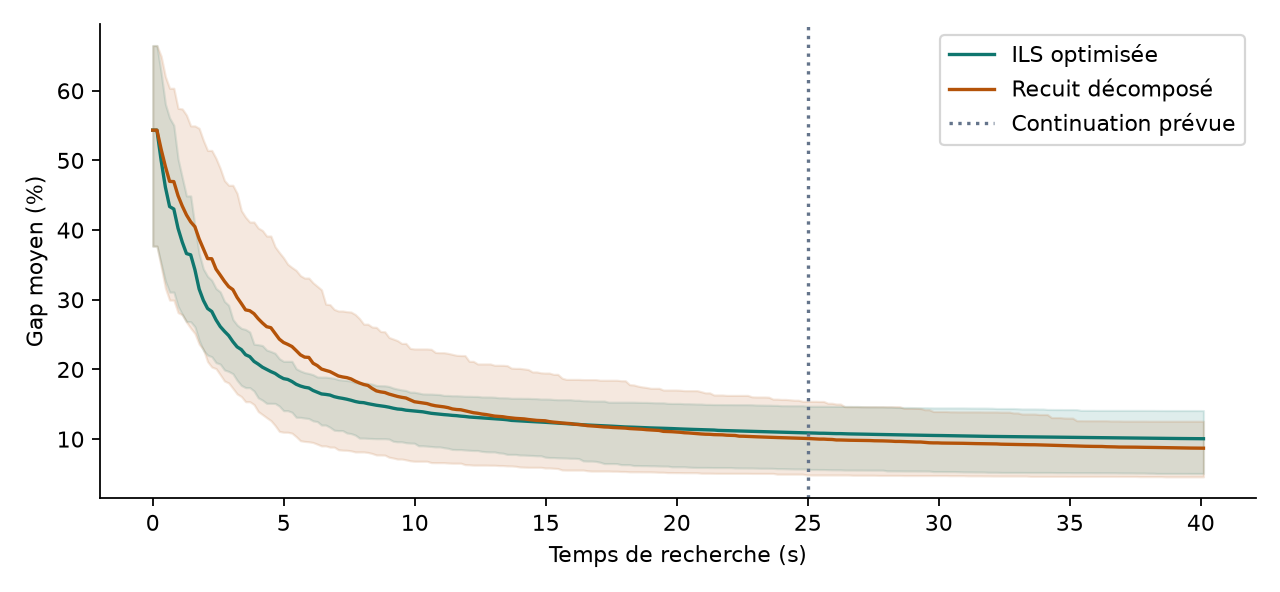

In [11]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_convergence.png')))

**Lecture.** La courbe est la moyenne des meilleurs gaps enregistrés ; la bande décrit les quartiles. Les traces sont reconstruites en escalier, sans inventer d'amélioration entre deux points. Le départ est ancré à zéro. Le passage à la seconde phase est déclaré ; la courbe ne représente pas le déplacement des véhicules.

### 6.2. Comparaison avant/après à budget égal

| Instance | Méthode | Essais | Gap moyen (%) | Pire gap (%) | Sous 5 % | Sous 6 % | Sous 7 % |
| --- | --- | --- | --- | --- | --- | --- | --- |
| C204 | ILS v1 réexécutée | 20 | 0,778 | 4,795 | 20 | 20 | 20 |
| C204 | ILS optimisée | 20 | 1,144 | 8,621 | 19 | 19 | 19 |
| R1_10_1 | ILS v1 réexécutée | 20 | 9,746 | 11,290 | 0 | 0 | 0 |
| R1_10_1 | ILS optimisée | 20 | 4,234 | 5,091 | 19 | 20 | 20 |

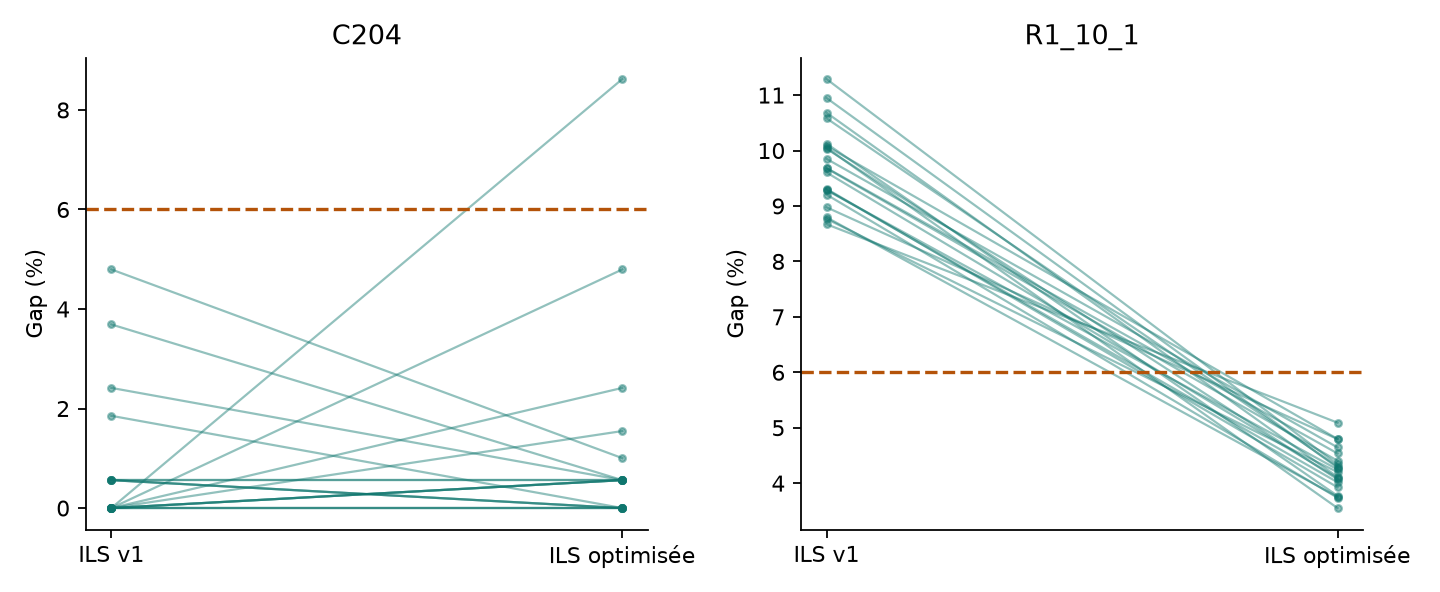

In [12]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_regression.png')))

**Lecture.** Les lignes relient les mêmes graines depuis le même départ. La version initiale est exécutée à nouveau depuis ses sources figées, dans les mêmes conditions que la version optimisée. Ce lot diagnostique deux cas connus ; il ne se substitue pas à la validation des 36 instances.

### 6.3. Pourquoi certains mouvements échouent

| Clients | Méthode | Rejet capacité (%) | Rejet horaire (%) | Mouvement accepté (%) | Propositions |
| --- | --- | --- | --- | --- | --- |
| 100 | ILS optimisée | 0,920 | 66,589 | 6,479 | 49960228 |
| 100 | Recuit décomposé | 0,884 | 63,551 | 3,932 | 883188224 |
| 200 | ILS optimisée | 6,946 | 54,523 | 14,801 | 22074323 |
| 200 | Recuit décomposé | 5,374 | 50,610 | 4,756 | 1015295488 |
| 1000 | ILS optimisée | 13,438 | 54,375 | 13,324 | 169036147 |
| 1000 | Recuit décomposé | 7,997 | 50,597 | 6,135 | 6370077184 |

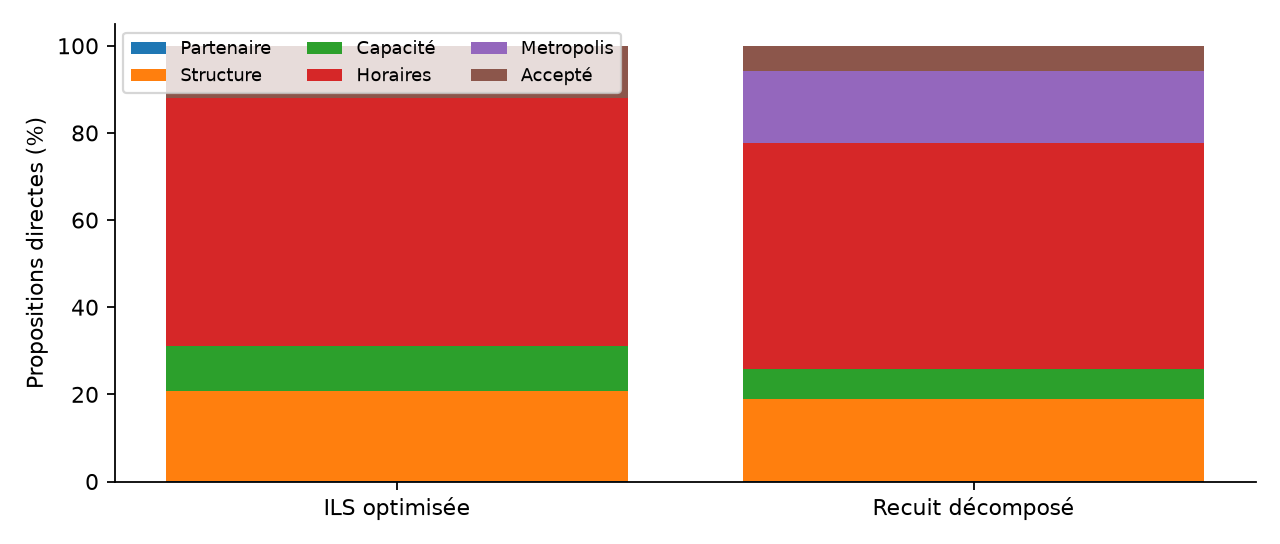

In [13]:
display(Image(filename=str(ROOT/'livraison/optimization_figures/v2_diagnostics.png')))

**Lecture.** Les proportions concernent les propositions directes. Un rejet temporel signifie que la fenêtre ou le retour devient impossible ; un rejet de capacité révèle une surcharge ; certains tirages ne définissent pas de mouvement utile. Ces compteurs localisent les pertes de travail sans prouver la cause unique d'un mauvais gap.

## 7. Implémentation, vérification et reproduction

Le code actif est `algo/optimized.py`, la boucle directe est dans `algo/iterated.py`, les mouvements dans `algo/direct.py` et les configurations dans `algo/profiles.py`. Le constructeur reste limité au démarrage. `algo/verify.py` recalcule indépendamment couverture unique, charge, fenêtre inclusive, retour et flotte. Les données ne sont pas modifiées pour obtenir un meilleur gap.

La suite inclut les bornes temporelles, les capacités, les arcs nuls du PLNE, les mouvements directs, la protection du record, les insertions comparées à une énumération et l'absence de réparation pendant les groupes. Le notebook exécute ses démonstrations et reconstruit les tableaux depuis les données mesurées ; il ne relance pas les campagnes à chaque lecture.

48 passed in 16.01s

Les sources et protocoles sont figés dans `results/optimization_v2/`. Les anciens résultats demeurent dans leurs dossiers avec leurs propres versions. La validation actuelle est indiquée par `livraison/VALIDATION.json` et `validation_livraison_ils.json`.

```powershell
.\.venv\Scripts\python.exe -m pytest tests
.\.venv\Scripts\python.exe cli.py C101 --method ils --seconds 5 --seed 1001
.\.venv\Scripts\python.exe -m streamlit run web/app.py
.\.venv\Scripts\python.exe scripts\analyze_optimization_v2.py --stage validation
.\.venv\Scripts\python.exe scripts\build_optimization_report.py
```

Les scripts de campagne reprennent les fichiers existants sans les remplacer. Une reproduction indépendante doit utiliser un autre dossier de campagne et un protocole distinct. Les exports CSV et JSON permettent de vérifier les moyennes et les solutions sans refaire toutes les recherches. L'interface permet aussi de lancer ses propres expériences et de simuler les horaires d'une solution contrôlée.

En CLI et dans l'interface, le budget d'un appel inclut sa construction si aucun départ n'est fourni. Les budgets du benchmark apparié portent sur l'amélioration depuis les départs communs sauvegardés. Une commande CLI de 25 secondes n'est donc pas une reproduction exacte d'un essai à 25 secondes d'amélioration plus construction.

In [14]:
ins=load(ROOT/'data/instances/C101.vrp')
result=solve(ins,production_settings('ils',seconds=.2,seed=1001))
assert verify(result['routes'],ins)['valid']
print('Démonstration ILS : distance',result['cost'],'; réalisable ; temps',round(result['runtime_s'],3),'s')


Démonstration ILS : distance

 827.3 ; réalisable ; temps 0.201 s


## 8. Limites et conclusion

L'ILS optimisée fournit 180/180 solutions réalisables ; son gap moyen équilibré est 4,933 %, son pire gap 24,321 %. À 1 000 clients, la moyenne porte sur douze instances et vaut 10,055 %. 8 de leurs moyennes atteignent ou dépassent 6 %. La moyenne ne remplace pas le détail par instance ni une garantie sur les futurs essais.

La capacité à traiter plusieurs milliers de clients n'est pas démontrée par ce lot arrêté à 1 000. Les matrices denses coûtent une mémoire quadratique et le choix des groupes reste heuristique. Les réglages sont évalués sur un lot limité ; ils ne sont pas universels. Le PLNE sert aux petits cas et ne certifie pas les grandes solutions.

Les prochains essais utiles portent sur le temps pour atteindre un seuil, la mémoire maximale, les cas dépassant encore la cible et la diversité des grandes instances. Une modification de paramètre doit être mesurée sur un protocole déclaré. La qualité d'un résultat tient à sa faisabilité, à la définition de sa référence et à la portée exacte de sa comparaison.

## Références

- Sujet CESI, *Algorithmique et optimisation*, pages projet et livrable final.
- Lourenço, Martin et Stützle, *Iterated Local Search*, https://arxiv.org/abs/math/0102188.
- Kirkpatrick, Gelatt et Vecchi, *Optimization by Simulated Annealing*, 1983, https://doi.org/10.1126/science.220.4598.671.
- PyVRP/Instances, convention DIMACS : https://github.com/PyVRP/Instances/blob/7474b068a8effa7f39448b241314b615c9271525/VRPTW/README.md.
- VRPLIB, lecture des instances : https://github.com/PyVRP/VRPLIB.
- SciPy, interface MILP/HiGHS : https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html.

## 9. Étude complémentaire de l’ILS à 1 000 clients

Cette section complète les campagnes v2 précédentes ; leurs chiffres ne sont pas remplacés ou mélangés. L’objectif reste la distance sous capacité et fenêtres strictes.

Nous avons exécuté 144 essais de développement sur six instances et 72 essais de validation sur douze autres instances, avec deux graines par variante. Les départs sont appariés. Le plafond de recherche est 20 secondes en développement et 40 secondes en validation ; construction et préchauffage sont distingués.

| Méthode | Essais | Gap moyen % | Écart-type | Pire gap % | Sous 6 % | Sous 7 % | Recherche s | Total s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS de référence | 24 | 10,127 | 5,903 | 25,086 | 7 | 11 | 40,008 | 44,422 |
| ILS–partitionnement | 24 | 10,355 | 6,443 | 28,012 | 9 | 11 | 38,039 | 42,422 |
| 64 voisins | 24 | 11,524 | 8,082 | 30,793 | 8 | 11 | 40,008 | 44,439 |

Les essais ne justifient pas de remplacer le moteur ILS de référence par défaut. Les nouvelles variantes restent expérimentales et leurs régressions sont conservées. L’écart-type agrégé mélange la difficulté des instances et la variabilité des graines. Avec deux graines, cette dernière reste imparfaitement estimée. Les échecs et régressions des variantes sont conservés dans l’étude détaillée.

La variante ILS–partitionnement conserve des tournées réalisables produites par quatre phases ILS et choisit une couverture exacte sous la limite de flotte. Son solveur optimise seulement l’archive disponible ; il ne certifie pas l’optimalité du problème complet. Le plafond de 40 secondes inclut ces phases et le partitionnement.

Le détail des choix, les références, l’ablation et les résultats par instance sont fournis dans `docs/AMELIORATIONS_ILS.md` et le notebook exécuté `Ameliorations_ILS_CVRPTW.ipynb`.

| instance | ILS de référence | 64 voisins | ILS–partitionnement |
| --- | --- | --- | --- |
| C1_10_3 | 3,802 | 3,203 | 3,029 |
| C1_10_4 | 4,088 | 3,808 | 3,946 |
| C2_10_3 | 10,503 | 12,914 | 11,538 |
| C2_10_4 | 13,366 | 12,712 | 13,494 |
| R1_10_3 | 6,789 | 6,449 | 6,519 |
| R1_10_4 | 5,528 | 6,705 | 6,033 |
| R2_10_3 | 11,255 | 12,690 | 11,910 |
| R2_10_4 | 16,654 | 29,216 | 18,876 |
| RC1_10_3 | 6,032 | 6,185 | 6,038 |
| RC1_10_4 | 5,473 | 5,093 | 4,969 |
| RC2_10_3 | 15,523 | 15,577 | 15,451 |
| RC2_10_4 | 22,509 | 23,736 | 22,462 |


### Archive combinée à effort supérieur

Une étude distincte réunit seize trajectoires admissibles par instance : dix résolutions ILS/recuit de v2 et six résolutions de la nouvelle validation. Les tournées sont recombinées pendant au plus deux secondes, puis la solution reçoit 60 secondes supplémentaires : un tiers d’ILS et deux tiers de recuit sur mouvements directs, graine 1501. Les résolutions d’origine sont toutes comptées dans l’effort, avec la construction v2 partagée comptée une seule fois par paire et les constructions v5 effectivement répétées.

Cette archive atteint **5.106 % de gap moyen**, avec un pire cas de **12.086 %** et un effort cumulé moyen de **745.7 secondes par instance**. Il s’agit d’une solution combinée par instance et de douze intensifications supplémentaires, pas d’une moyenne de répétitions indépendantes ni d’un solveur obtenant ce résultat en 40 ou 60 secondes. La baisse de 6,600 % à cette moyenne mesure l’amélioration de cette archive précise ; elle ne démontre pas la supériorité du relais sur un autre algorithme à effort total égal. L’objectif sous 6 % est atteint en moyenne dans ce périmètre coûteux, pas sur chaque instance ni dans le protocole court.

| Instance | Avant intensification % | Archive finale % | Effort cumulé s |
| --- | --- | --- | --- |
| C1_10_3 | 1,668 | 1,563 | 745,446 |
| C1_10_4 | 2,878 | 2,309 | 739,547 |
| C2_10_3 | 4,069 | 3,080 | 742,431 |
| C2_10_4 | 8,579 | 5,000 | 745,518 |
| R1_10_3 | 4,568 | 3,078 | 739,793 |
| R1_10_4 | 3,741 | 3,009 | 739,516 |
| R2_10_3 | 9,512 | 9,049 | 754,095 |
| R2_10_4 | 13,397 | 10,443 | 754,827 |
| RC1_10_3 | 4,583 | 3,236 | 738,519 |
| RC1_10_4 | 3,439 | 2,867 | 738,931 |
| RC2_10_3 | 10,118 | 5,549 | 752,397 |
| RC2_10_4 | 12,652 | 12,086 | 757,287 |

Les résultats complets sont dans `results/optimization_v5/portfolio_intensified/`. L’archive initiale reste disponible dans `portfolio/` ; aucune référence BKS n’est passée au moteur de recherche.


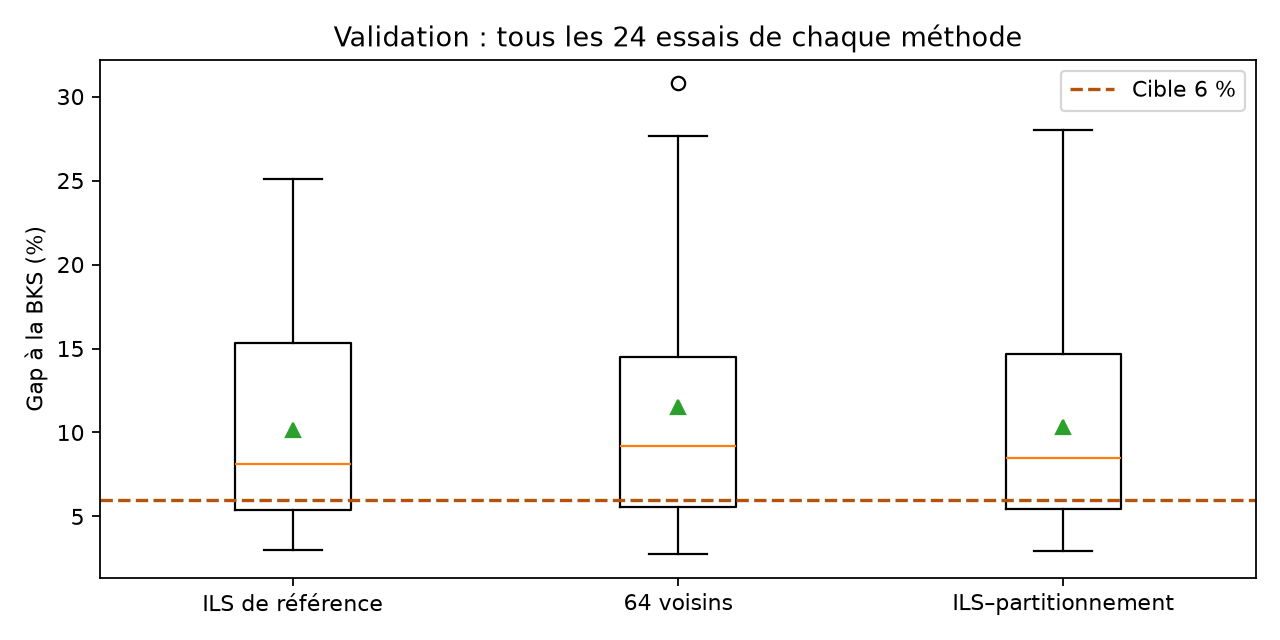

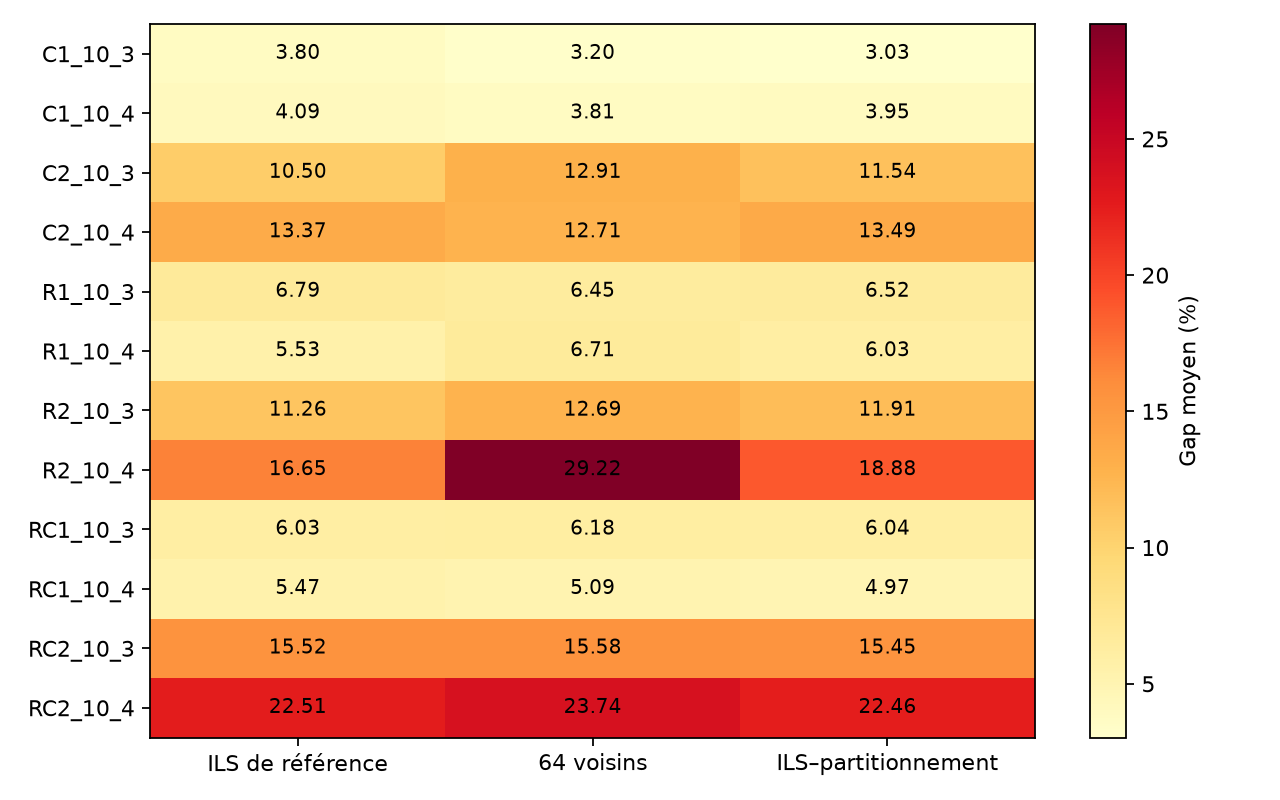

In [15]:
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/validation.png')))
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/instances.png')))

## 10. Cache des évaluations et regroupement temporel

Cette nouvelle étude CVRPTW ajoute un cache exact du préfixe inchangé des tournées et une sélection spatiale et temporelle de tournées complètes. Les contrôles et l’objectif restent identiques. Les résultats v5 précédents restent identifiés par leur propre lot.

Après 48 essais de réglage sur six instances, 48 essais appariés de confirmation portent sur douze autres instances à 1 000 clients, deux graines et un plafond de 40 secondes, avec construction séparée.

| Méthode | Essais | Gap moyen % | Écart-type | Pire gap % | Sous 6 % | Sous 7 % | Recherche s | Total s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS de référence | 24 | 6,065 | 3,836 | 17,063 | 12 | 16 | 40,009 | 44,268 |
| Cache et groupes temporels | 24 | 6,164 | 3,735 | 15,468 | 12 | 13 | 40,010 | 44,339 |

Les résultats ne satisfont pas notre règle exploratoire de confirmation : le moteur de référence reste le défaut. L’amélioration appariée est -0.099 point, intervalle exploratoire [-0.547 ; 0.318]. Les résultats détaillés, l’ablation et les limites figurent dans `docs/AMELIORATIONS_ILS_V6.md` et le notebook exécuté `Ameliorations_ILS_V6.ipynb`.

Un suivi exploratoire ajoute 24 résolutions du cache seul en réutilisant les 24 mesures de référence. Son gap moyen est 6.207 %, contre 6.065 % pour la référence. Ce suivi est effectué après lecture de la confirmation et ne constitue pas une nouvelle validation indépendante.

En combinant les trois trajectoires issues de chaque même couple instance/graine, les 24 ensembles obtiennent 5.508 % de gap moyen, pire 14.406 %, pour un effort cumulé moyen de 132.7 secondes. Ces trois recherches et leurs constructions sont toutes facturées. Il manque une référence unique au même effort total pour conclure à une supériorité ; ce bilan ne remplace pas la comparaison à 40 secondes.

Sur trois cas difficiles, six essais supplémentaires à 120 secondes repartent de l’archive déjà optimisée. La moyenne de l’archive à douze instances devient 4.749 %, pire cas 11.173 %, avec un effort cumulé moyen de 805.7 secondes par instance. Neuf solutions restent inchangées ; les trois autres facturent les deux branches de recherche. Ce bilan à budgets hétérogènes ne remplace pas la comparaison à 40 secondes.


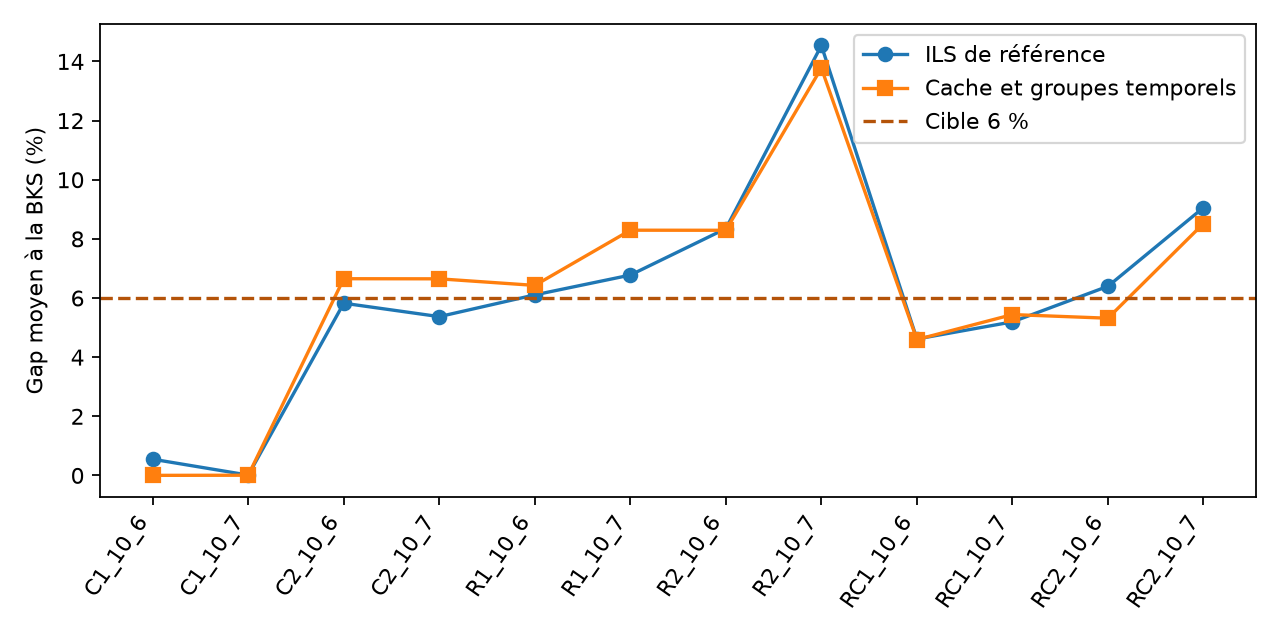

In [16]:
display(Image(filename=str(ROOT/'livraison/ils_v6_figures/validation.png')))